# 01 · Explore and clean the job postings

This notebook tells the story behind the cleaning rules in `src/hiring_intel/clean.py`.

- The **logic** lives in `clean.py`, so the daily pipeline and the tests use it.
- This notebook **imports** that logic and shows *why* each rule exists.

**To run:** activate the project's `.venv`, run `pip install jupyter matplotlib`, then open this notebook and pick the `.venv` kernel.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from hiring_intel.clean import EXCLUDE_TITLE, clean_jobs, newest_file, salary_training_set

pd.set_option("display.max_colwidth", 60)

# Chart style: one blue for data, gray for context, light grid, no top/right borders.
BLUE, GRAY, INK, MUTED = "#2a78d6", "#a3a29c", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5cf", "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

def money_k(x, _=None):
    return f"${x/1000:,.0f}K"

## 1. What we collected

In [3]:
source_file = newest_file()
raw = pd.read_csv(source_file)
jobs = clean_jobs(raw)

print(f"File: {source_file.name}")
print(f"Jobs: {len(jobs):,}  |  Companies: {jobs['company'].nunique()}  |  Bay Area share: {jobs['is_bay_area'].mean():.0%}")
jobs.groupby("source")["company"].agg(companies="nunique", jobs="size")

File: jobs_2026-10-27.csv
Jobs: 3,563  |  Companies: 12  |  Bay Area share: 36%


,companies,jobs
source,,
ashby,7,1312
greenhouse,4,1945
lever,1,306


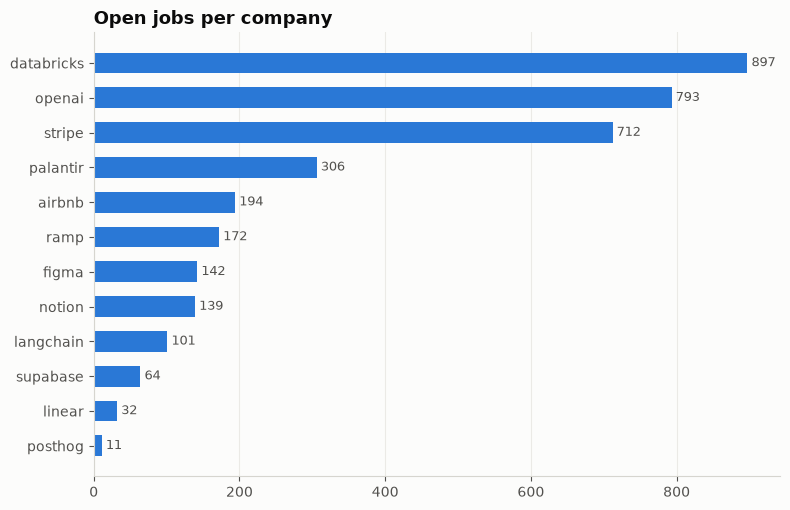

In [4]:
per_company = jobs["company"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 0.35 * len(per_company) + 1))
ax.barh(per_company.index, per_company.values, color=BLUE, height=0.6)
ax.bar_label(ax.containers[0], padding=3, color=MUTED, fontsize=9)
ax.set_title("Open jobs per company")
ax.grid(axis="y", visible=False)
plt.tight_layout()

A few companies make up most of the rows. That's a risk: the salary model could learn "what OpenAI pays" instead of "what this role pays." Adding 100+ companies fixes this.

## 2. How many jobs list a salary?

In [5]:
coverage = (jobs["salary_source"].fillna("none")
            .value_counts().rename_axis("salary source").to_frame("jobs"))
coverage["share"] = (coverage["jobs"] / len(jobs)).map("{:.0%}".format)
coverage

,jobs,share
salary source,,
none,1755,49%
text,1014,28%
structured,794,22%


- **structured** = the platform gave us min, max, currency and interval as fields
- **text** = our regex found a range like `$160K – $210K` in the description
- **none** = no pay range we could find

Only rows with a salary can be used to *train* the salary model. Every row is still useful for skill-demand analysis.

## 3. Problems in the raw salaries

Looking at the raw numbers showed salaries of **$57** and a maximum of **$1.06M**. Neither is a real yearly US salary. Checking currency and pay interval explains both.

In [6]:
with_pay = jobs[jobs["salary_min"].notna()]
display(with_pay["salary_currency"].value_counts().to_frame("jobs"))
display(with_pay["salary_interval"].value_counts().to_frame("jobs"))

,jobs
salary_currency,
USD,1783
GBP,11
CAD,11
SGD,2
SEK,1


,jobs
salary_interval,
1 YEAR,1800
1 MONTH,5
1 HOUR,3


In [7]:
cols = ["company", "title", "salary_min", "salary_max", "salary_currency", "salary_interval"]
print("Not USD or not yearly:")
odd = with_pay[(with_pay["salary_currency"] != "USD") | (with_pay["salary_interval"] != "1 YEAR")]
display(odd[cols].head(10))

print("Intern / contract titles:")
display(with_pay[with_pay["title"].str.contains(EXCLUDE_TITLE, na=False)][cols].head(10))

Not USD or not yearly:


,company,title,salary_min,salary_max,salary_currency,salary_interval
49,openai,IT Support Specialist,60.58,108.17,USD,1 HOUR
94,openai,"Software Engineer, ChatGPT Infrastructure",194000.00,280000.00,GBP,1 YEAR
186,openai,Member of Executive Operations,62.98,110.58,USD,1 HOUR
222,openai,"Quality Engineer, Rack Infrastructure & Site Operations",171000.00,345000.00,SGD,1 YEAR
312,openai,"Researcher, Training - London",170000.00,445000.00,GBP,1 YEAR
367,openai,"Software Engineer, Model Deployment- ChatGPT Engineering",194000.00,280000.00,GBP,1 YEAR
379,openai,PCBA Manufacturing Engineer,171000.00,345000.00,SGD,1 YEAR
384,openai,"Cyber Operations Strategist, Critical Harm Operations",140000.00,188000.00,CAD,1 YEAR
457,openai,Support Delivery Lead - Toronto,297000.00,330000.00,CAD,1 YEAR
463,openai,Senior Support Engineer - Toronto,261000.00,290000.00,CAD,1 YEAR


Intern / contract titles:


,company,title,salary_min,salary_max,salary_currency,salary_interval
508,openai,Recruiting Coordinator - Contract,57.0,70.0,USD,1 HOUR
705,openai,"Legal Contract Manager, Public Sector",216000.0,240000.0,USD,1 YEAR
920,ramp,Applied Scientist Intern,12500.0,12500.0,USD,1 MONTH
935,ramp,"Software Engineering Intern, Frontend",12500.0,12500.0,USD,1 MONTH
937,ramp,"Software Engineering Intern, Backend",12500.0,12500.0,USD,1 MONTH
938,ramp,"Software Engineering Intern, Android",12500.0,12500.0,USD,1 MONTH
939,ramp,"Software Engineering Intern, iOS",12500.0,12500.0,USD,1 MONTH
954,ramp,Technical Sourcer | Engineering (Contract),90000.0,150000.0,USD,1 YEAR
2379,databricks,Candidate Experience Admin (6-month contract),70000.0,80000.0,USD,1 YEAR
2380,databricks,Candidate Experience Admin (6-month contract),70000.0,85000.0,USD,1 YEAR


What we found on the first run (Oct 27):

| Problem | Example | Rule |
|---|---|---|
| Foreign currency | Swedish analyst role at 770K–1.06M **SEK** (about $100K) | keep USD only |
| Hourly pay | IT support at $57–$110 **per hour** | keep yearly only |
| Monthly pay | Interns at $12,500 **per month** | keep yearly only |
| Different pay scale | Intern and contract roles | drop by title |
| Parsing mistakes | anything outside $30K–$1.5M | range check |

The very high values ($380K–$850K research roles at top AI labs) are **real** and stay in.

## 4. Apply the cleaning rules

In [8]:
train, dropped = salary_training_set(jobs)

steps = ["All jobs"] + [f"− {reason}" for reason in dropped]
remaining = [len(jobs)]
for n in dropped.values():
    remaining.append(remaining[-1] - n)

funnel = pd.DataFrame({"step": steps, "rows left": remaining,
                       "dropped": [0] + list(dropped.values())})
funnel

,step,rows left,dropped
0,All jobs,3563,0
1,− no salary,1808,1755
2,− not USD,1783,25
3,− not yearly,1775,8
4,− intern/contract,1768,7
5,− max below min,1768,0
6,− out of range,1766,2


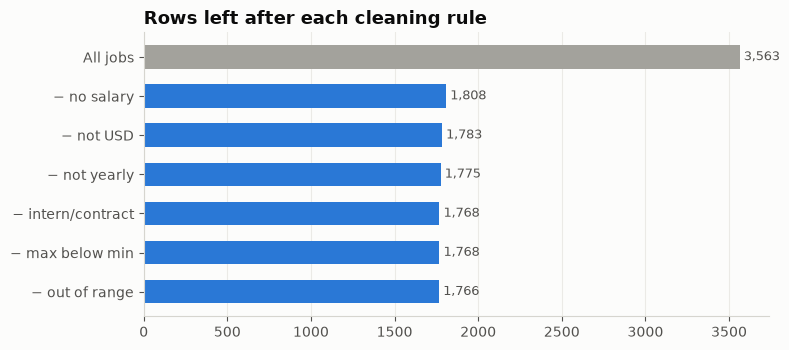

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [GRAY] + [BLUE] * (len(remaining) - 1)
bars = ax.barh(steps[::-1], remaining[::-1], color=colors[::-1], height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in remaining[::-1]], padding=3, color=MUTED, fontsize=9)
ax.set_title("Rows left after each cleaning rule")
ax.grid(axis="y", visible=False)
plt.tight_layout()

The biggest drop is **no salary**, not bad data. The quality rules together remove only a few dozen rows, which means the raw data is mostly trustworthy once we check currency and interval.

`clean.py` logs these same counts on every run. If one of them suddenly jumps, a platform probably changed its format.

## 5. What salaries look like after cleaning

1,766 training rows


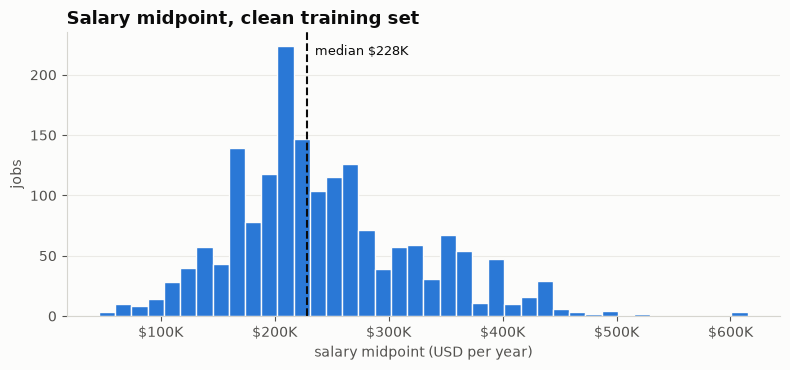

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(train["salary_mid"], bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
median = train["salary_mid"].median()
ax.axvline(median, color=INK, linewidth=1.5, linestyle="--")
ax.annotate(f"median {money_k(median)}", (median, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK, fontsize=9)
ax.xaxis.set_major_formatter(money_k)
ax.set_title("Salary midpoint, clean training set")
ax.set_xlabel("salary midpoint (USD per year)")
ax.set_ylabel("jobs")
ax.grid(axis="x", visible=False)
plt.tight_layout()
print(f"{len(train):,} training rows")

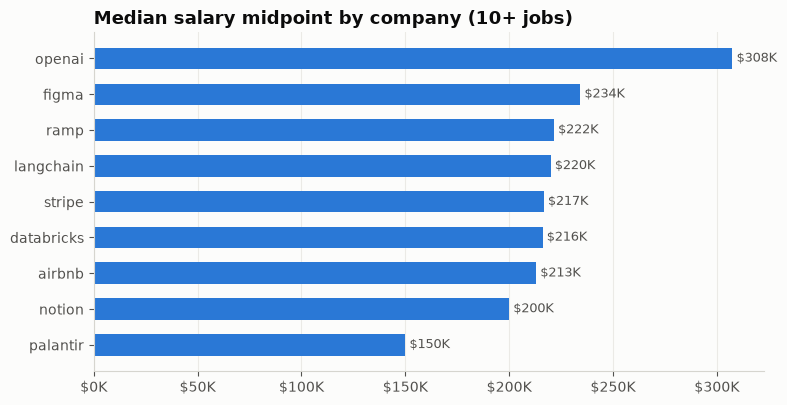

In [11]:
by_company = (train.groupby("company")["salary_mid"]
              .agg(jobs="size", median="median")
              .query("jobs >= 10").sort_values("median"))
fig, ax = plt.subplots(figsize=(8, 0.35 * len(by_company) + 1))
ax.barh(by_company.index, by_company["median"], color=BLUE, height=0.6)
ax.bar_label(ax.containers[0], labels=[money_k(v) for v in by_company["median"]],
             padding=3, color=MUTED, fontsize=9)
ax.xaxis.set_major_formatter(money_k)
ax.set_title("Median salary midpoint by company (10+ jobs)")
ax.grid(axis="y", visible=False)
plt.tight_layout()

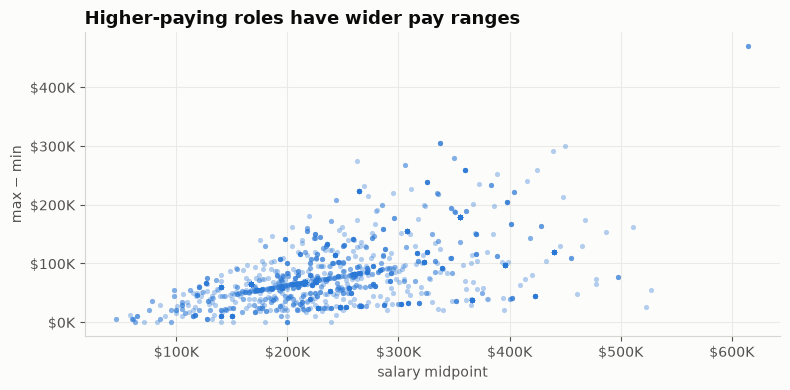

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train["salary_mid"], train["salary_spread"], s=14, color=BLUE, alpha=0.35, linewidths=0)
ax.xaxis.set_major_formatter(money_k)
ax.yaxis.set_major_formatter(money_k)
ax.set_title("Higher-paying roles have wider pay ranges")
ax.set_xlabel("salary midpoint")
ax.set_ylabel("max − min")
plt.tight_layout()

In [13]:
train.groupby(train["is_bay_area"].map({True: "Bay Area", False: "Elsewhere"}))["salary_mid"] \
     .describe()[["count", "25%", "50%", "75%"]].style.format("{:,.0f}")

,count,25%,50%,75%
is_bay_area,,,,
Bay Area,"1,030","213,500","259,500","326,000"
Elsewhere,736,"167,500","213,000","238,500"


## 6. Takeaways

1. **About half the postings list a salary**, enough to train a model on day one.
2. **Five specific problems** (currency, hourly, monthly, interns/contract, out-of-range) each became one rule and one test in `clean.py`.
3. **A few companies dominate** the data. Next step: grow `config/companies.yaml` to 100+ companies.
4. **Pay ranges get wider as pay goes up.** We predict the midpoint for now. Predicting min and max separately is a later upgrade.

**Next:** extract skills (Python, PyTorch, Docker...) from descriptions. They become the model's main features.